# Hafta 5 · Model Değerlendirme ve Kümeleme

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde sınıflandırma metriklerini notlardaki çözümlü örneklerle doğrulayacak, meme kanseri verisinde çapraz doğrulama yapacak ve k-means ile kümeleme deneyeceksiniz.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. Karışıklık matrisi ve metrikler (Çözümlü Örnek 5.1)
1000 kişi: 50 hasta (1), 950 sağlıklı (0). Model 40 hastayı yakalamış, 30 sağlıklı kişiye “hasta” demiş.

In [2]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
# Örnek 5.1: 50 hasta (1), 950 sağlıklı (0)
y_gercek = np.array([1] * 50 + [0] * 950)
y_tahmin = np.array([1] * 40 + [0] * 10 + [1] * 30 + [0] * 920)

tn, fp, fn, tp = confusion_matrix(y_gercek, y_tahmin).ravel()
print("TP, FN, FP, TN:", tp, fn, fp, tn)
print(f"Doğruluk  : {accuracy_score(y_gercek, y_tahmin):.3f}")
print(f"Kesinlik  : {precision_score(y_gercek, y_tahmin):.3f}")
print(f"Duyarlılık: {recall_score(y_gercek, y_tahmin):.3f}")
print(f"Özgüllük  : {tn / (tn + fp):.3f}")
print(f"F1        : {f1_score(y_gercek, y_tahmin):.3f}")

TP, FN, FP, TN: 40 10 30 920
Doğruluk  : 0.960
Kesinlik  : 0.571
Duyarlılık: 0.800
Özgüllük  : 0.968
F1        : 0.667


### Doğruluk paradoksu

In [3]:
y_hep0 = np.zeros_like(y_gercek)      # herkese "sağlıklı" der
print("doğruluk:", accuracy_score(y_gercek, y_hep0),
      "| duyarlılık:", recall_score(y_gercek, y_hep0))

doğruluk: 0.95 | duyarlılık: 0.0


### Alıştırma (Değerlendirme Sorusu 8)
200 e-postanın 40'ı spam; filtre 35 e-postayı spam olarak işaretlemiş, bunların 30'u gerçekten spam. Önce elle hesaplayın.

In [ ]:
y_g = np.array([1] * 40 + [0] * 160)
y_t = np.array([1] * 30 + [0] * 10 + [1] * 5 + [0] * 155)
print(confusion_matrix(y_g, y_t))
print(f"doğruluk={accuracy_score(y_g, y_t):.3f}  kesinlik={precision_score(y_g, y_t):.3f}")
print(f"duyarlılık={recall_score(y_g, y_t):.3f}  F1={f1_score(y_g, y_t):.3f}")

## 2. ROC eğrisi, AUC ve ortalama kesinlik (Çözümlü Örnek 5.2 ve 5.3)

AUC: 0.8125
AP : 0.854


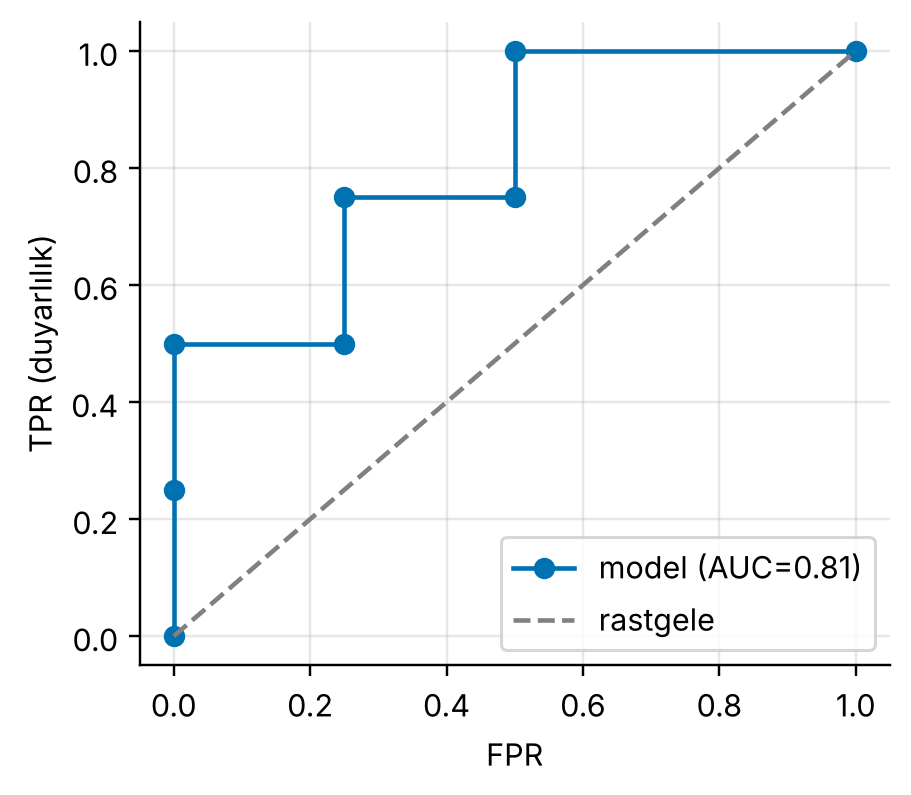

In [5]:
from sklearn.metrics import (roc_auc_score, roc_curve,
                             average_precision_score)
import matplotlib.pyplot as plt
skor = [0.95, 0.85, 0.75, 0.65, 0.55, 0.45, 0.35, 0.20]
sinif = [1, 1, 0, 1, 0, 1, 0, 0]             # 1 = P, 0 = N
auc = roc_auc_score(sinif, skor)
print("AUC:", auc)
print("AP :", round(average_precision_score(sinif, skor), 3))
fpr, tpr, esik = roc_curve(sinif, skor)
plt.figure(figsize=(4.4, 3.8))
plt.plot(fpr, tpr, "o-", label=f"model (AUC={auc:.2f})")
plt.plot([0, 1], [0, 1], "--", c="gray", label="rastgele")
plt.xlabel("FPR"); plt.ylabel("TPR (duyarlılık)")
plt.legend(); plt.show()

### Alıştırma (Değerlendirme Sorusu 11)
Skorlara göre sıralanmış beş örneğin etiketleri +, −, +, +, −. AP ve AUC'yi önce elle hesaplayın.

In [ ]:
y11 = [1, 0, 1, 1, 0]
s11 = [5, 4, 3, 2, 1]                        # büyükten küçüğe skorlar
print("AP :", round(average_precision_score(y11, s11), 3))
print("AUC:", round(roc_auc_score(y11, s11), 3))

## 3. Meme kanseri verisinde çapraz doğrulama
Veri %75 eğitim / %25 test olarak katmanlı bölünür; model seçimi yalnızca eğitim kümesinde 5-katlı çapraz doğrulamayla yapılır.

In [7]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

X, y = load_breast_cancer(return_X_y=True)   # meme kanseri (ikili)
X_egt, X_test, y_egt, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=0)
model = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=1000))

# 5-katlı çapraz doğrulama (F1 ölçütüyle)
skorlar = cross_val_score(model, X_egt, y_egt, cv=5, scoring="f1")
print("Kat F1:", skorlar.round(3))
print(f"ÇD F1: {skorlar.mean():.3f} ± {skorlar.std():.3f}")

Kat F1: [0.964 0.982 0.971 0.981 1.   ]
ÇD F1: 0.980 ± 0.012


### Test kümesinde karışıklık matrisi, rapor ve AUC

In [8]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
model.fit(X_egt, y_egt)
y_tahmin = model.predict(X_test)
print(confusion_matrix(y_test, y_tahmin))
print(classification_report(y_test, y_tahmin, digits=3))
print("AUC:", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))

[[50  3]
 [ 3 87]]
              precision    recall  f1-score   support

           0      0.943     0.943     0.943        53
           1      0.967     0.967     0.967        90

    accuracy                          0.958       143
   macro avg      0.955     0.955     0.955       143
weighted avg      0.958     0.958     0.958       143

AUC: 0.9951781970649896


## 4. k-means ile kümeleme ve dirsek yöntemi
300 noktalı, 4 kümeli yapay veri (make_blobs).

[[ 9.52  0.5 ]
 [-1.32  4.55]
 [ 0.1  -8.73]
 [-8.44  5.47]]
WCSS: 571.3


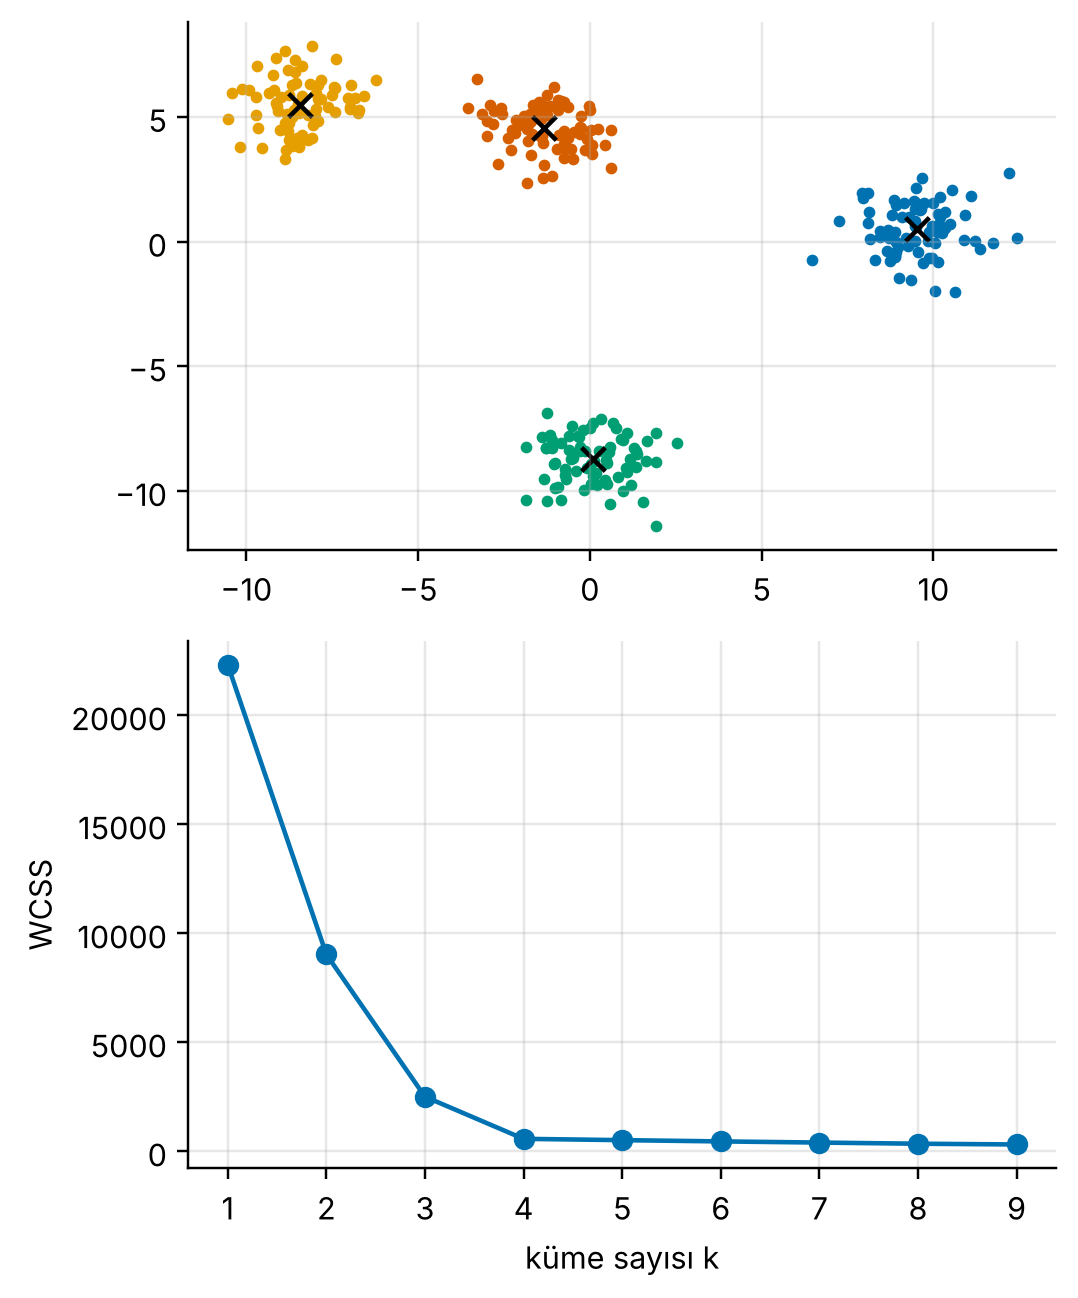

In [9]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
Xk, _ = make_blobs(n_samples=300, centers=4, random_state=7)
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(Xk)
print(km.cluster_centers_.round(2))           # merkezler
print("WCSS:", round(km.inertia_, 1))
wcss = [KMeans(k, n_init=10, random_state=0).fit(Xk).inertia_
        for k in range(1, 10)]                   # dirsek yöntemi
fig, (a1, a2) = plt.subplots(2, 1, figsize=(5, 6))
for j in range(4):
    a1.scatter(*Xk[km.labels_ == j].T, s=8)
a1.scatter(*km.cluster_centers_.T, c="k", marker="x", s=60)
a2.plot(range(1, 10), wcss, "o-")
a2.set_xlabel("küme sayısı k"); a2.set_ylabel("WCSS")
plt.tight_layout(); plt.show()

### Çözümlü Örnek 5.6'yı doğrulayın
Başlangıç merkezleri A(1, 1) ve D(5, 7).

In [10]:
P6 = np.array([[1, 1], [1.5, 2], [3, 3.5], [5, 7], [3.5, 5], [4.5, 5]])
km2 = KMeans(n_clusters=2, init=np.array([[1, 1], [5, 7]]), n_init=1).fit(P6)
print("küme etiketleri:", km2.labels_)
print("merkezler:", km2.cluster_centers_.round(3).tolist())

küme etiketleri: [0 0 0 1 1 1]
merkezler: [[1.833, 2.167], [4.333, 5.667]]
